In [3]:
import pandas as pd
import glob
import geopandas as gpd
import matplotlib.pyplot as plt
from tqdm import tqdm

base_dir = "/kaggle/input/datasets/jeffsinsel/nyc-fhvhv-data"
zones = gpd.read_file("/kaggle/input/datasets/jeffsinsel/nyc-fhvhv-data/taxi_zones/taxi_zones.shp")
files = sorted(glob.glob(f"{base_dir}/fhvhv_tripdata_*.parquet"))

man = zones[zones['borough'] == "Manhattan"]


#are not in the df data
zones_to_remove = [103, 104, 202, 105]
man = man[~man['LocationID'].isin(zones_to_remove)]

manID = man["LocationID"].to_list()

zone_to_idx = {loc: i for i, loc in enumerate(manID)}

partials = []
for f in tqdm(files, desc="Aggregating"):
    d = pd.read_parquet(f, columns=["pickup_datetime", "trip_time",
                                     "base_passenger_fare",
                                     "PULocationID", "DOLocationID"])
    d["pickup_datetime"] = pd.to_datetime(d["pickup_datetime"])
    d = d[d["pickup_datetime"].dt.hour.isin([7, 8, 9])]
    d = d[d["PULocationID"].isin(manID) & d["DOLocationID"].isin(manID)]

    d["PULocationID"] = d["PULocationID"].map(zone_to_idx)
    d["DOLocationID"] = d["DOLocationID"].map(zone_to_idx)
    d["minute"] = d["pickup_datetime"].dt.hour * 60 + d["pickup_datetime"].dt.minute
    d["trip_minutes"] = d["trip_time"] / 60.0
    d["day"] = d["pickup_datetime"].dt.normalize()

    partials.append(d[["minute", "PULocationID", "DOLocationID",
                        "trip_minutes", "base_passenger_fare", "day"]])

data = pd.concat(partials, ignore_index=True)
del partials
print(data.shape)

Aggregating: 100%|██████████| 46/46 [02:32<00:00,  3.32s/it]


(27795148, 6)


In [21]:
data.loc[(data["trip_minutes"] <= 1) | (data["trip_minutes"] > 3*60), "trip_minutes"] = pd.NA
data.loc[(data["base_passenger_fare"] <= 3) | (data["base_passenger_fare"] > 500), "base_passenger_fare"] = pd.NA

In [22]:
print(data["trip_minutes"].describe())
print(data["base_passenger_fare"].describe())

count    2.778635e+07
mean     1.547171e+01
std      8.576686e+00
min      1.016667e+00
25%      9.366667e+00
50%      1.371667e+01
75%      1.965000e+01
max      1.799833e+02
Name: trip_minutes, dtype: float64
count    2.732657e+07
mean     1.537941e+01
std      9.684591e+00
min      3.010000e+00
25%      8.600000e+00
50%      1.294000e+01
75%      1.966000e+01
max      4.997200e+02
Name: base_passenger_fare, dtype: float64


In [ ]:
n_days = data["day"].nunique()

## Daily realized request counts: required for Poisson validation.
'''''
daily_counts = (
    data.groupby(["day", "minute", "PULocationID", "DOLocationID"])
    .size()
    .rename("count")
    .reset_index()
    .rename(columns={
        "minute": "time_stamp",
        "PULocationID": "origin",
        "DOLocationID": "destination",
    })
)
'''

# should export daily counts as CSV here

# one row per (minute, origin, destination): trip count, avg travel time, avg price
grp = data.groupby(["minute", "PULocationID", "DOLocationID"])
matrix = grp.agg(
    travel_time=("trip_minutes", "mean"),
    price=("base_passenger_fare", "mean"),
).join(grp.size().rename("trips")).reset_index()

# per-day expected demand (this is the "demand" field the json needs)
matrix["demand"] = matrix["trips"] / n_days

matrix = matrix.rename(columns={"minute": "time_stamp",
                                "PULocationID": "origin",
                                "DOLocationID": "destination"})
matrix = matrix[["time_stamp", "origin", "destination", "demand", "travel_time", "price"]]


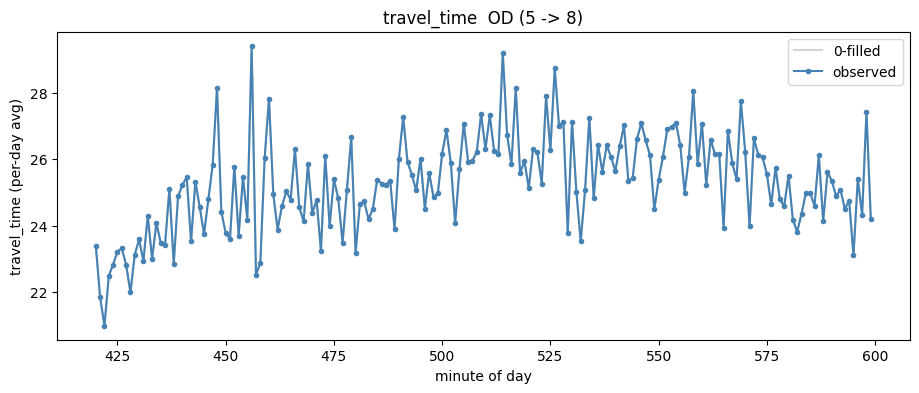

In [27]:
o, d = 5, 8   # origin, destination zone index (change these)

x = "travel_time"
# the 7-10am window is minutes 420..599 (matches your filter)
window = range(7*60, 10*60)

sub = matrix[(matrix["origin"] == o) & (matrix["destination"] == d)]
# reindex onto EVERY minute in the window so gaps become explicit (missing -> NaN)
s = sub.set_index("time_stamp")[x].reindex(window)

plt.figure(figsize=(11, 4))
plt.plot(s.index, s.fillna(0).values, color="lightgray", label="0-filled")   # gaps as 0
plt.plot(s.index, s.values, marker="o", ms=3, color="steelblue", label="observed")  # NaN breaks the line
plt.xlabel("minute of day")
plt.ylabel(f"{x} (per-day avg)")
plt.title(f"{x}  OD ({o} -> {d})")
plt.legend()
plt.show()

In [36]:
matrix.to_csv("manhattan_matrix.csv", index=False)